# Experiments 003 to 006: A100 subject accuracy and tier validation

This notebook updates `004_2_analysis_plots.ipynb` using only the A100 results.
It keeps the seed-0 stages from experiments 003, 004, 005 and 006 so the cross-experiment
comparison remains matched by seed.

The main question is whether the proposed easy, medium and hard subject tiers still match
the observed difficulty after removing the older T4 runs. Experiment 006 seed variation is
analysed separately in `006_1_analysis_plots.ipynb`; this notebook stays a seed-0 tier snapshot.

This notebook reads saved artifacts only and does not need a GPU. Figures are saved to
`analysis/figures/006_2/`.


In [1]:
# find the repo root and set up the A100 subject-analysis figure folder
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color

RES = ROOT / "results"
R3 = RES / "003_COLAB_FULL_B3_sft_grpo_seed0"
B3 = RES / "base_evals" / "003_COLAB_FULL_B3"
R4 = RES / "004_COLAB_FULL_B3_base_grpo_seed0"
B4 = RES / "base_evals" / "004_COLAB_FULL_B3"
R5 = RES / "005_COLAB_FULL_B05_base_grpo_seed0"
B5 = RES / "base_evals" / "005_COLAB_FULL_B05"
R6 = RES / "006_COLAB_FULL_B05_sft_grpo_seed0"
B6 = RES / "base_evals" / "006_COLAB_FULL_B05"
FIG = ROOT / "analysis" / "figures" / "006_2"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("default")
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759"}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

print("figures ->", FIG)


figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/006_2


## Analysis scope

The proposal describes the tier memberships as initial and says they should be checked against
pilot base-model zero-shot accuracy. Generative exact-match is the registered primary metric,
but it also depends on prompt following, response format and answer extraction. The letter
log-probability probe is kept beside it because it is less affected by those generation issues.

Experiments 003 and 004 are the 3B A100 runs. Experiments 005 and 006 are the 0.5B A100 runs.
The repeated base rows are kept visible so agreement can be checked instead of assumed.


In [2]:
# load every A100 experiment and keep each training stage visible
from data.subjects import TIERS as SUBJECT_TIERS, TIERS_PROPOSAL
from scipy.stats import spearmanr

SUBJECTS = [subject for tier in ["easy", "medium", "hard"] for subject in SUBJECT_TIERS[tier]]
SUBJECT_TIER = {subject: tier for tier, members in SUBJECT_TIERS.items() for subject in members}
SUBJECT_LABELS = {
    "high_school_psychology": "HS psychology",
    "marketing": "marketing",
    "business_ethics": "business ethics",
    "high_school_geography": "HS geography",
    "philosophy": "philosophy",
    "us_foreign_policy": "US foreign policy",
    "high_school_mathematics": "HS mathematics",
    "formal_logic": "formal logic",
}

RUN_SPECS = [
    ("003", "3B", [
        ("base", B3 / "base_preds.jsonl", B3 / "base_logprob_preds.jsonl"),
        ("SFT", R3 / "sft_preds.jsonl", R3 / "sft_logprob_preds.jsonl"),
        ("SFT+GRPO", R3 / "grpo_preds.jsonl", R3 / "grpo_logprob_preds.jsonl"),
    ]),
    ("004", "3B", [
        ("base", B4 / "base_preds.jsonl", B4 / "base_logprob_preds.jsonl"),
        ("base+GRPO", R4 / "grpo_preds.jsonl", R4 / "grpo_logprob_preds.jsonl"),
    ]),
    ("005", "0.5B", [
        ("base", B5 / "base_preds.jsonl", B5 / "base_logprob_preds.jsonl"),
        ("base+GRPO", R5 / "grpo_preds.jsonl", R5 / "grpo_logprob_preds.jsonl"),
    ]),
    ("006", "0.5B", [
        ("base", B6 / "base_preds.jsonl", B6 / "base_logprob_preds.jsonl"),
        ("SFT", R6 / "sft_preds.jsonl", R6 / "sft_logprob_preds.jsonl"),
        ("SFT+GRPO", R6 / "grpo_preds.jsonl", R6 / "grpo_logprob_preds.jsonl"),
    ]),
]

for run_dir in [R3, R4, R5, R6]:
    manifest = jload(run_dir / "manifest.json")
    if "A100" not in manifest["gpu"]["device"]:
        raise ValueError(f"expected an A100 run in {run_dir}")

SOURCE_ROWS = {}
subject_records = []
ROW_ORDER = []
reference_keys = None

for experiment, scale, stages in RUN_SPECS:
    for stage, gen_path, probe_path in stages:
        row_label = f"{experiment} | {scale} | {stage}"
        ROW_ORDER.append(row_label)
        for metric, path in [("generative", gen_path), ("probe", probe_path)]:
            rows = jsonl(path)
            keys = [(row["subject"], row["gold"]) for row in rows]
            if len(rows) != 1884:
                raise ValueError(f"expected 1884 rows in {path}, found {len(rows)}")
            if reference_keys is None:
                reference_keys = keys
            elif keys != reference_keys:
                raise ValueError(f"found misaligned test items in {path}")
            SOURCE_ROWS[(experiment, stage, metric)] = rows
            for subject in SUBJECTS:
                values = [int(row["correct"]) for row in rows if row["subject"] == subject]
                if not values:
                    raise ValueError(f"found no rows for {subject} in {path}")
                subject_records.append({
                    "experiment": experiment,
                    "scale": scale,
                    "stage": stage,
                    "row_label": row_label,
                    "metric": metric,
                    "subject": subject,
                    "tier": SUBJECT_TIER[subject],
                    "n": len(values),
                    "correct": int(sum(values)),
                    "accuracy": float(np.mean(values)),
                })

SUBJECT_DF = pd.DataFrame(subject_records)
assert SOURCE_ROWS[("005", "base", "generative")] == SOURCE_ROWS[("006", "base", "generative")]
assert SOURCE_ROWS[("005", "base", "probe")] == SOURCE_ROWS[("006", "base", "probe")]
print(f"loaded {len(SOURCE_ROWS)} aligned A100 prediction files")
display(SUBJECT_DF[SUBJECT_DF["metric"] == "generative"]
        .drop_duplicates("subject")[["subject", "tier", "n"]]
        .set_index("subject"))


loaded 20 aligned A100 prediction files


,tier,n
subject,,
high_school_psychology,easy,545
marketing,easy,234
us_foreign_policy,easy,100
high_school_geography,medium,198
philosophy,medium,311
business_ethics,medium,100
high_school_mathematics,hard,270
formal_logic,hard,126


subject,HS psychology,marketing,US foreign policy,HS geography,philosophy,business ethics,HS mathematics,formal logic
row_label,,,,,,,,
003 | 3B | base,67.7,70.9,63.0,53.0,51.4,59.0,51.9,44.4
003 | 3B | SFT,67.5,51.3,54.0,55.1,43.1,47.0,46.3,38.9
003 | 3B | SFT+GRPO,84.0,82.1,79.0,68.7,66.2,72.0,54.4,46.8
004 | 3B | base,67.5,70.5,61.0,55.1,50.2,63.0,56.3,38.9
004 | 3B | base+GRPO,79.8,77.4,67.0,61.1,60.5,68.0,60.4,41.3
005 | 0.5B | base,22.2,19.7,28.0,12.6,19.6,16.0,10.0,19.8
005 | 0.5B | base+GRPO,46.8,56.8,41.0,44.4,31.5,36.0,23.7,29.4
006 | 0.5B | base,22.2,19.7,28.0,12.6,19.6,16.0,10.0,19.8
006 | 0.5B | SFT,22.4,21.8,37.0,20.2,18.3,19.0,16.7,17.5


saved fig17_subject_accuracy_a100_all_stages


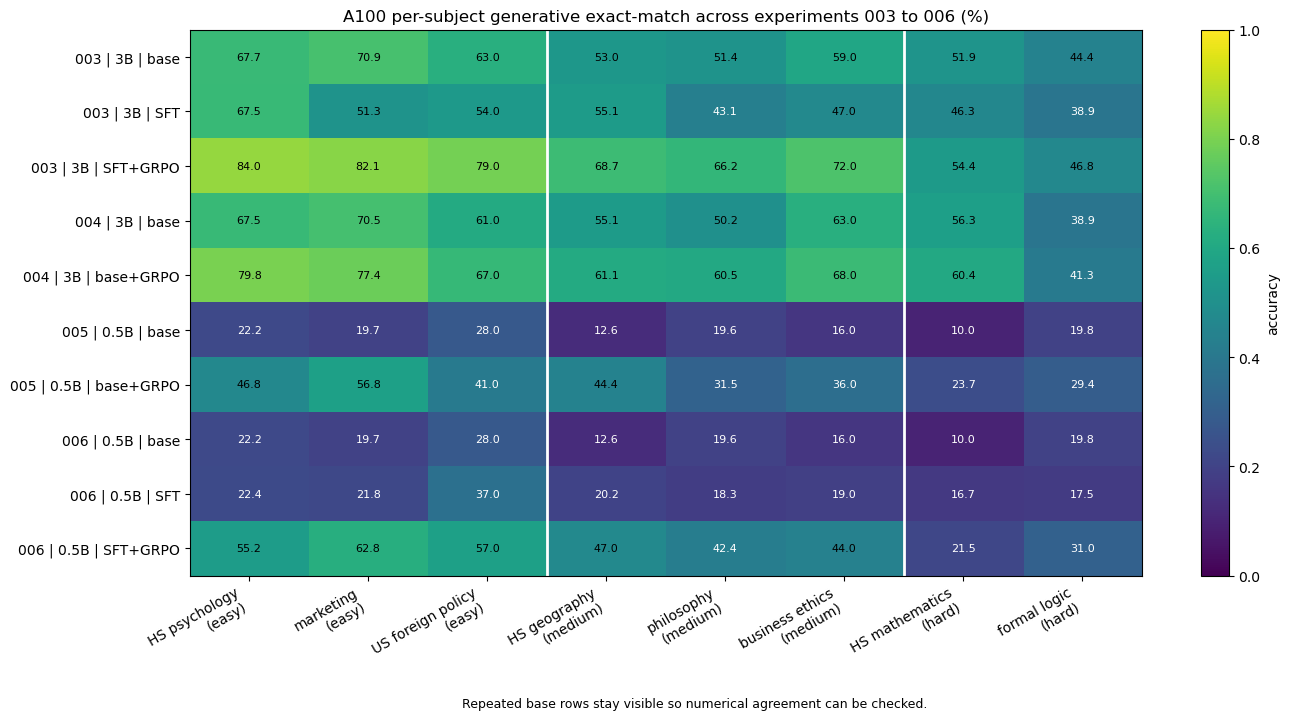

In [3]:
# plot all A100 generative stages in one subject matrix
gen_matrix = (SUBJECT_DF[SUBJECT_DF["metric"] == "generative"]
              .pivot(index="row_label", columns="subject", values="accuracy")
              .reindex(index=ROW_ORDER, columns=SUBJECTS))

display((100 * gen_matrix).round(1).rename(columns={subject: SUBJECT_LABELS[subject] for subject in SUBJECTS}))

fig, ax = plt.subplots(figsize=(14, 7.2))
image = ax.imshow(gen_matrix.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1)
for row_index in range(gen_matrix.shape[0]):
    for col_index in range(gen_matrix.shape[1]):
        value = gen_matrix.iloc[row_index, col_index]
        text_color = heatmap_text_color(image, value)
        ax.text(col_index, row_index, f"{100 * value:.1f}", ha="center", va="center", color=text_color, fontsize=8)
xlabels = [f"{SUBJECT_LABELS[subject]}\n({SUBJECT_TIER[subject]})" for subject in SUBJECTS]
ax.set_xticks(np.arange(len(SUBJECTS)))
ax.set_xticklabels(xlabels, rotation=30, ha="right")
ax.set_yticks(np.arange(len(ROW_ORDER)))
ax.set_yticklabels(ROW_ORDER)
ax.grid(False)
ax.axvline(2.5, color="white", lw=2)
ax.axvline(5.5, color="white", lw=2)
ax.set_title("A100 per-subject generative exact-match across experiments 003 to 006 (%)")
fig.colorbar(image, ax=ax, label="accuracy")
fig.text(0.5, 0.01, "Repeated base rows stay visible so numerical agreement can be checked.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
save(fig, "fig17_subject_accuracy_a100_all_stages")
plt.show()


saved fig18_subject_final_endpoints_a100


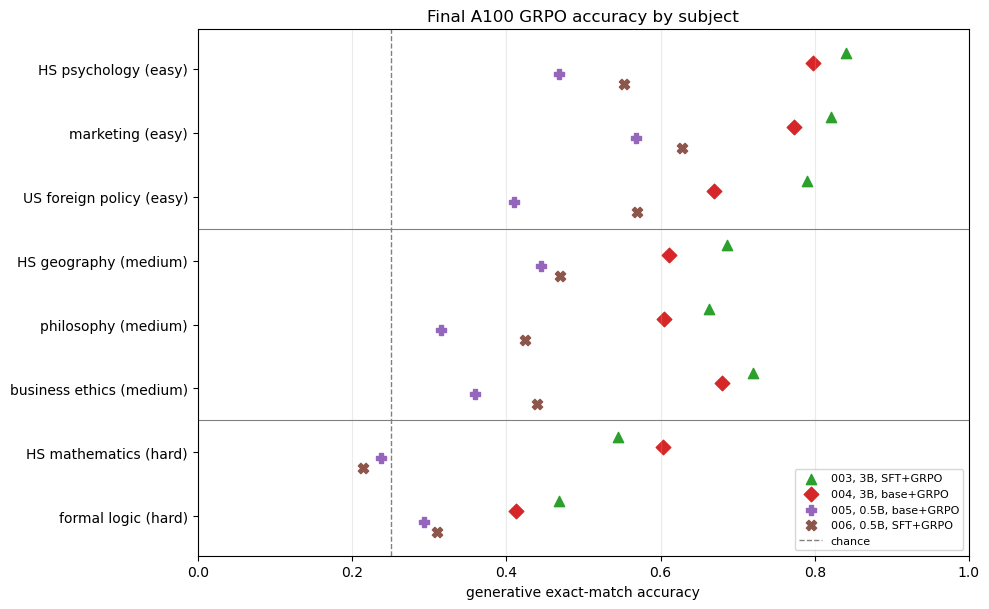

In [4]:
# compare the four final A100 GRPO endpoints without hiding subject variation
FINAL_SOURCES = [
    ("003 | 3B | SFT+GRPO", "003, 3B, SFT+GRPO", "^", "tab:green"),
    ("004 | 3B | base+GRPO", "004, 3B, base+GRPO", "D", "tab:red"),
    ("005 | 0.5B | base+GRPO", "005, 0.5B, base+GRPO", "P", "tab:purple"),
    ("006 | 0.5B | SFT+GRPO", "006, 0.5B, SFT+GRPO", "X", "tab:brown"),
]
ypos = np.arange(len(SUBJECTS))
offsets = np.linspace(-0.24, 0.24, len(FINAL_SOURCES))
fig, ax = plt.subplots(figsize=(10, 6.2))
for offset, (row_label, label, marker, color) in zip(offsets, FINAL_SOURCES):
    values = gen_matrix.loc[row_label, SUBJECTS].to_numpy()
    ax.scatter(values, ypos + offset, s=55, marker=marker, label=label, color=color)
ax.axvline(0.25, color="grey", ls="--", lw=1, label="chance")
ax.axhline(2.5, color="grey", lw=0.8)
ax.axhline(5.5, color="grey", lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{SUBJECT_LABELS[s]} ({SUBJECT_TIER[s]})" for s in SUBJECTS])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("generative exact-match accuracy")
ax.set_title("Final A100 GRPO accuracy by subject")
ax.grid(alpha=0.25, axis="x")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save(fig, "fig18_subject_final_endpoints_a100")
plt.show()


saved fig19_base_subject_difficulty_a100


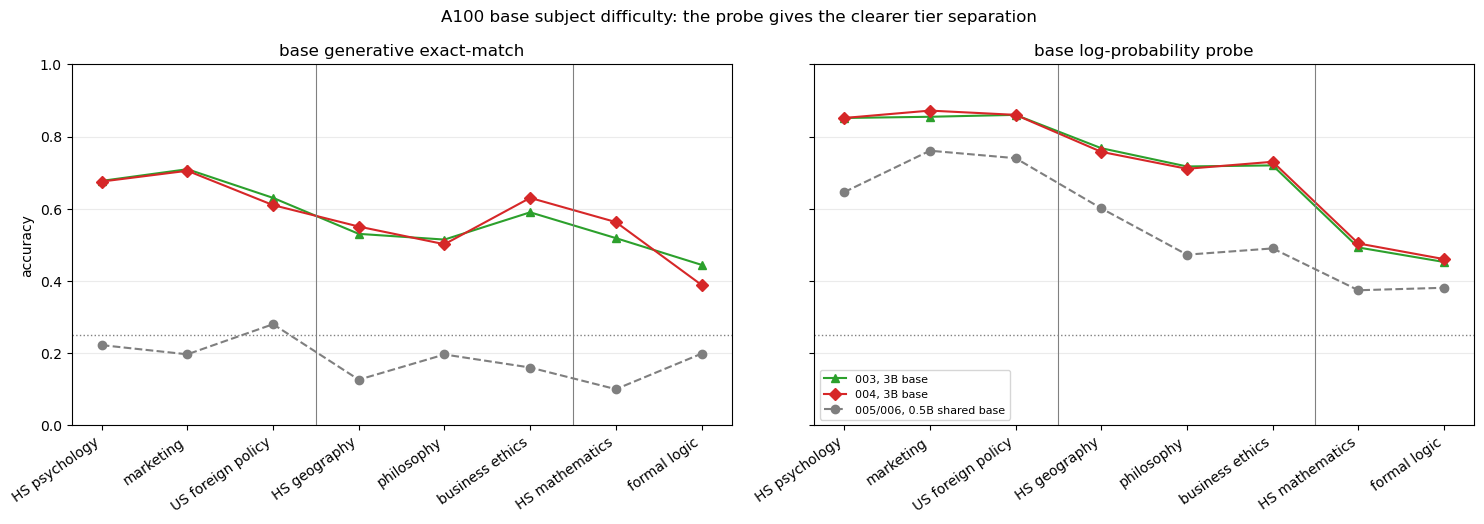

,same_prediction,same_correctness
comparison,,
"0.5B base generation, 005 vs 006",1.0000,1.0000
"0.5B base probe, 005 vs 006",1.0000,1.0000
"3B base generation, 003 vs 004",0.8355,0.8891
"3B base probe, 003 vs 004",0.9862,0.9899


In [5]:
# compare A100 base generation with the format-neutral base probe
BASE_SOURCES = [
    ("003 | 3B | base", "003, 3B base", "^", "-", "tab:green"),
    ("004 | 3B | base", "004, 3B base", "D", "-", "tab:red"),
    ("005 | 0.5B | base", "005/006, 0.5B shared base", "o", "--", "tab:gray"),
]
xpos = np.arange(len(SUBJECTS))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.3), sharey=True)
for ax, metric, title in [
    (axes[0], "generative", "base generative exact-match"),
    (axes[1], "probe", "base log-probability probe"),
]:
    metric_frame = (SUBJECT_DF[SUBJECT_DF["metric"] == metric]
                    .pivot(index="row_label", columns="subject", values="accuracy"))
    for row_label, label, marker, line_style, color in BASE_SOURCES:
        values = metric_frame.loc[row_label, SUBJECTS].to_numpy()
        ax.plot(xpos, values, marker=marker, ls=line_style, label=label, color=color)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.axvline(2.5, color="grey", lw=0.8)
    ax.axvline(5.5, color="grey", lw=0.8)
    ax.set_xticks(xpos)
    ax.set_xticklabels([SUBJECT_LABELS[s] for s in SUBJECTS], rotation=35, ha="right")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.grid(alpha=0.25, axis="y")
axes[0].set_ylabel("accuracy")
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("A100 base subject difficulty: the probe gives the clearer tier separation")
fig.tight_layout()
save(fig, "fig19_base_subject_difficulty_a100")
plt.show()

# measure repeated-base agreement before treating small rank changes as real
def row_agreement(rows_a, rows_b):
    if [(row["subject"], row["gold"]) for row in rows_a] != [(row["subject"], row["gold"]) for row in rows_b]:
        raise ValueError("found base files with different item alignment")
    return {
        "same_prediction": np.mean([a["pred"] == b["pred"] for a, b in zip(rows_a, rows_b)]),
        "same_correctness": np.mean([bool(a["correct"]) == bool(b["correct"]) for a, b in zip(rows_a, rows_b)]),
    }

agreement_rows = []
for label, source_a, source_b in [
    ("0.5B base generation, 005 vs 006", ("005", "base", "generative"), ("006", "base", "generative")),
    ("0.5B base probe, 005 vs 006", ("005", "base", "probe"), ("006", "base", "probe")),
    ("3B base generation, 003 vs 004", ("003", "base", "generative"), ("004", "base", "generative")),
    ("3B base probe, 003 vs 004", ("003", "base", "probe"), ("004", "base", "probe")),
]:
    agreement_rows.append({"comparison": label, **row_agreement(SOURCE_ROWS[source_a], SOURCE_ROWS[source_b])})
agreement_tbl = pd.DataFrame(agreement_rows).set_index("comparison")
display(agreement_tbl.round(4))


In [6]:
# quantify tier ordering with equal subject weight
SOURCE_DEFS = [
    ("003 base gen", "003 | 3B | base", "generative"),
    ("003 base probe", "003 | 3B | base", "probe"),
    ("003 SFT gen", "003 | 3B | SFT", "generative"),
    ("003 final gen", "003 | 3B | SFT+GRPO", "generative"),
    ("003 final probe", "003 | 3B | SFT+GRPO", "probe"),
    ("004 base gen", "004 | 3B | base", "generative"),
    ("004 base probe", "004 | 3B | base", "probe"),
    ("004 final gen", "004 | 3B | base+GRPO", "generative"),
    ("004 final probe", "004 | 3B | base+GRPO", "probe"),
    ("005/006 base gen", "005 | 0.5B | base", "generative"),
    ("005/006 base probe", "005 | 0.5B | base", "probe"),
    ("005 final gen", "005 | 0.5B | base+GRPO", "generative"),
    ("005 final probe", "005 | 0.5B | base+GRPO", "probe"),
    ("006 SFT gen", "006 | 0.5B | SFT", "generative"),
    ("006 final gen", "006 | 0.5B | SFT+GRPO", "generative"),
    ("006 final probe", "006 | 0.5B | SFT+GRPO", "probe"),
]

def accuracy_map(row_label, metric):
    subset = SUBJECT_DF[(SUBJECT_DF["row_label"] == row_label) & (SUBJECT_DF["metric"] == metric)]
    return dict(zip(subset["subject"], subset["accuracy"]))

def pair_order_rate(acc, easier_tier, harder_tier, mapping=SUBJECT_TIERS):
    comparisons = [acc[easier] > acc[harder] for easier in mapping[easier_tier] for harder in mapping[harder_tier]]
    return float(np.mean(comparisons))

tier_rows = []
tier_codes = {"easy": 0, "medium": 1, "hard": 2}
for label, row_label, metric in SOURCE_DEFS:
    acc = accuracy_map(row_label, metric)
    difficulty = [1 - acc[subject] for subject in SUBJECTS]
    assigned = [tier_codes[SUBJECT_TIER[subject]] for subject in SUBJECTS]
    rho, p_value = spearmanr(assigned, difficulty)
    tier_rows.append({
        "source": label,
        "easy_macro": np.mean([acc[s] for s in SUBJECT_TIERS["easy"]]),
        "medium_macro": np.mean([acc[s] for s in SUBJECT_TIERS["medium"]]),
        "hard_macro": np.mean([acc[s] for s in SUBJECT_TIERS["hard"]]),
        "easy>medium pairs": pair_order_rate(acc, "easy", "medium"),
        "medium>hard pairs": pair_order_rate(acc, "medium", "hard"),
        "easy>hard pairs": pair_order_rate(acc, "easy", "hard"),
        "easy-hard boundary": min(acc[s] for s in SUBJECT_TIERS["easy"]) - max(acc[s] for s in SUBJECT_TIERS["hard"]),
        "spearman_rho": rho,
        "spearman_p": p_value,
    })

tier_validation_tbl = pd.DataFrame(tier_rows).set_index("source")
display(tier_validation_tbl.round(3))


,easy_macro,medium_macro,hard_macro,easy>medium pairs,medium>hard pairs,easy>hard pairs,easy-hard boundary,spearman_rho,spearman_p
source,,,,,,,,,
003 base gen,0.672,0.545,0.481,1.000,0.833,1.000,0.111,0.882,0.004
003 base probe,0.855,0.735,0.472,1.000,1.000,1.000,0.359,0.945,0.000
003 SFT gen,0.576,0.484,0.426,0.778,0.833,1.000,0.050,0.731,0.039
003 final gen,0.817,0.690,0.506,1.000,1.000,1.000,0.246,0.945,0.000
003 final probe,0.856,0.740,0.486,1.000,1.000,1.000,0.338,0.945,0.000
004 base gen,0.663,0.561,0.476,0.889,0.667,1.000,0.047,0.743,0.035
004 base probe,0.861,0.733,0.482,1.000,1.000,1.000,0.348,0.945,0.000
004 final gen,0.747,0.632,0.508,0.889,1.000,1.000,0.066,0.869,0.005
004 final probe,0.853,0.731,0.480,1.000,1.000,1.000,0.343,0.945,0.000


saved fig20_final_tier_macro_a100


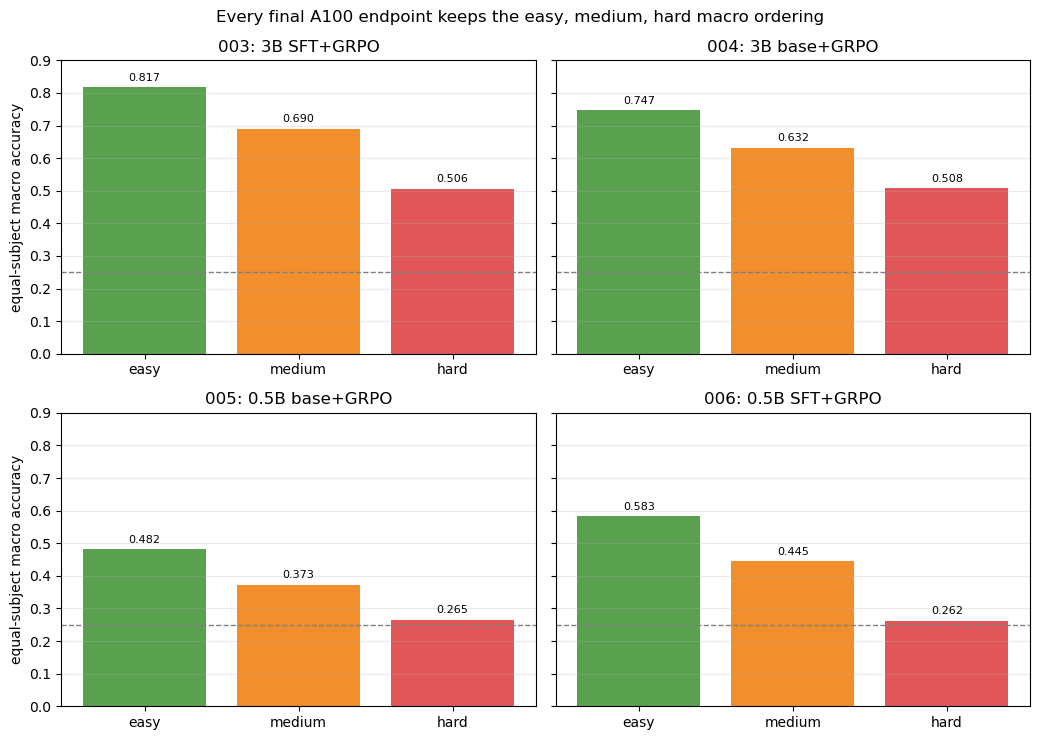

In [7]:
# plot macro tier ordering for the four final A100 endpoints
FINAL_MACRO = [
    ("003 | 3B | SFT+GRPO", "003: 3B SFT+GRPO"),
    ("004 | 3B | base+GRPO", "004: 3B base+GRPO"),
    ("005 | 0.5B | base+GRPO", "005: 0.5B base+GRPO"),
    ("006 | 0.5B | SFT+GRPO", "006: 0.5B SFT+GRPO"),
]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.5), sharey=True)
for ax, (row_label, title) in zip(axes.flat, FINAL_MACRO):
    acc = accuracy_map(row_label, "generative")
    values = [np.mean([acc[s] for s in SUBJECT_TIERS[tier]]) for tier in ["easy", "medium", "hard"]]
    bars = ax.bar(["easy", "medium", "hard"], values, color=[TIER_COLORS[tier] for tier in ["easy", "medium", "hard"]])
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.3f}", ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, 0.9)
    ax.axhline(0.25, color="grey", ls="--", lw=1)
    ax.grid(alpha=0.25, axis="y")
axes[0, 0].set_ylabel("equal-subject macro accuracy")
axes[1, 0].set_ylabel("equal-subject macro accuracy")
fig.suptitle("Every final A100 endpoint keeps the easy, medium, hard macro ordering")
fig.tight_layout()
save(fig, "fig20_final_tier_macro_a100")
plt.show()


,metric,delta,ci_lo,ci_hi
source,,,,
003 base gen,generative,0.1115,-0.0019,0.1920
003 base probe,probe,0.3588,0.2604,0.3989
003 final gen,generative,0.2456,0.1426,0.3162
003 final probe,probe,0.3384,0.2403,0.3830
004 base gen,generative,0.0470,-0.0700,0.1419
004 base probe,probe,0.3477,0.2559,0.3920
004 final gen,generative,0.0663,-0.0422,0.1696
004 final probe,probe,0.3426,0.2403,0.3880
005/006 shared base gen,generative,-0.0018,-0.0904,0.0725


saved fig21_easy_hard_boundary_a100


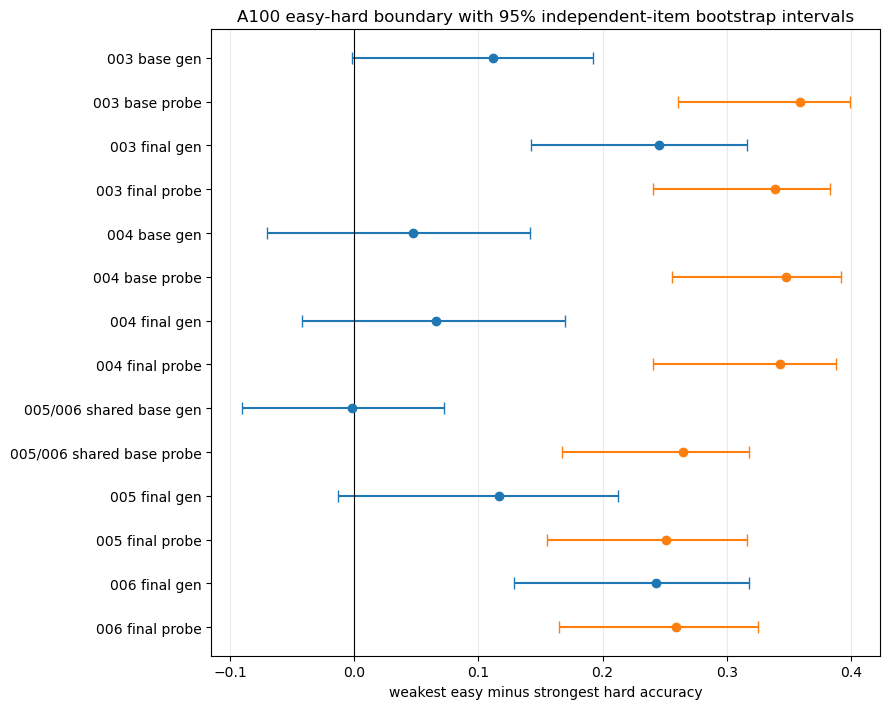

In [8]:
# bootstrap the full easy-hard boundary instead of choosing one subject pair
def tier_boundary_ci(rows, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    boot_means = {}
    point_means = {}
    members = SUBJECT_TIERS["easy"] + SUBJECT_TIERS["hard"]
    for subject in members:
        values = np.asarray([int(row["correct"]) for row in rows if row["subject"] == subject], dtype=float)
        point_means[subject] = float(values.mean())
        indices = rng.integers(0, len(values), size=(n_boot, len(values)))
        boot_means[subject] = values[indices].mean(axis=1)
    point = min(point_means[s] for s in SUBJECT_TIERS["easy"]) - max(point_means[s] for s in SUBJECT_TIERS["hard"])
    boot_easy = np.vstack([boot_means[s] for s in SUBJECT_TIERS["easy"]]).min(axis=0)
    boot_hard = np.vstack([boot_means[s] for s in SUBJECT_TIERS["hard"]]).max(axis=0)
    boot_delta = boot_easy - boot_hard
    return point, float(np.percentile(boot_delta, 2.5)), float(np.percentile(boot_delta, 97.5))

BOUNDARY_SOURCES = [
    ("003 base gen", ("003", "base", "generative"), "generative"),
    ("003 base probe", ("003", "base", "probe"), "probe"),
    ("003 final gen", ("003", "SFT+GRPO", "generative"), "generative"),
    ("003 final probe", ("003", "SFT+GRPO", "probe"), "probe"),
    ("004 base gen", ("004", "base", "generative"), "generative"),
    ("004 base probe", ("004", "base", "probe"), "probe"),
    ("004 final gen", ("004", "base+GRPO", "generative"), "generative"),
    ("004 final probe", ("004", "base+GRPO", "probe"), "probe"),
    ("005/006 shared base gen", ("005", "base", "generative"), "generative"),
    ("005/006 shared base probe", ("005", "base", "probe"), "probe"),
    ("005 final gen", ("005", "base+GRPO", "generative"), "generative"),
    ("005 final probe", ("005", "base+GRPO", "probe"), "probe"),
    ("006 final gen", ("006", "SFT+GRPO", "generative"), "generative"),
    ("006 final probe", ("006", "SFT+GRPO", "probe"), "probe"),
]

BOUNDARY_SEEDS = {
    "005/006 shared base gen": 100,
    "005/006 shared base probe": 101,
    "005 final gen": 102,
    "005 final probe": 103,
    "006 final gen": 104,
    "006 final probe": 105,
    "003 base gen": 106,
    "003 base probe": 107,
    "004 base gen": 108,
    "004 base probe": 109,
    "004 final gen": 110,
    "004 final probe": 111,
    "003 final gen": 112,
    "003 final probe": 113,
}

boundary_rows = []
for label, source, metric in BOUNDARY_SOURCES:
    delta, lo, hi = tier_boundary_ci(SOURCE_ROWS[source], seed=BOUNDARY_SEEDS[label])
    boundary_rows.append({"source": label, "metric": metric, "delta": delta, "ci_lo": lo, "ci_hi": hi})

boundary_tbl = pd.DataFrame(boundary_rows).set_index("source")
display(boundary_tbl.round(4))

fig, ax = plt.subplots(figsize=(9, 7.2))
for index, (source, row) in enumerate(boundary_tbl.iterrows()):
    color = "tab:blue" if row["metric"] == "generative" else "tab:orange"
    ax.errorbar(row["delta"], index,
                xerr=np.array([[row["delta"] - row["ci_lo"]], [row["ci_hi"] - row["delta"]]]),
                fmt="o", capsize=4, color=color)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(boundary_tbl)))
ax.set_yticklabels(boundary_tbl.index)
ax.invert_yaxis()
ax.set_xlabel("weakest easy minus strongest hard accuracy")
ax.set_title("A100 easy-hard boundary with 95% independent-item bootstrap intervals")
ax.grid(alpha=0.25, axis="x")
fig.tight_layout()
save(fig, "fig21_easy_hard_boundary_a100")
plt.show()


,metric,delta,ci_lo,ci_hi
source,,,,
003 base gen,generative,0.04,-0.09,0.17
003 base probe,probe,0.14,0.03,0.25
003 final gen,generative,0.07,-0.05,0.19
003 final probe,probe,0.11,0.00,0.22
004 base gen,generative,-0.02,-0.15,0.11
004 base probe,probe,0.13,0.02,0.24
004 final gen,generative,-0.01,-0.14,0.12
004 final probe,probe,0.13,0.02,0.24
005/006 shared base gen,generative,0.12,0.01,0.23


saved fig22_easy_medium_swap_a100


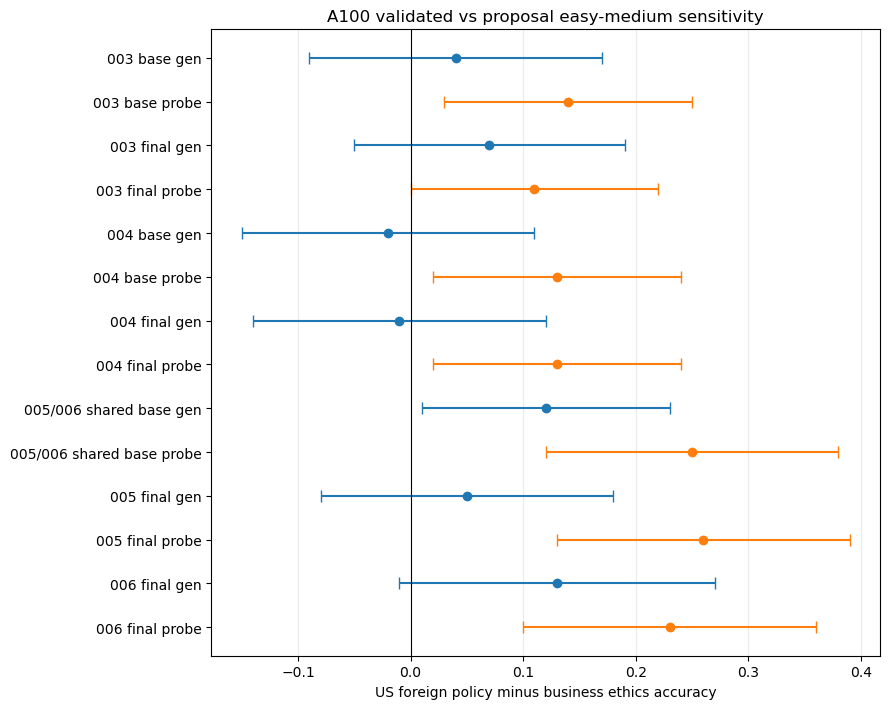

In [9]:
# keep the easy-medium membership difference as a sensitivity check
def independent_subject_delta_ci(rows, subject_a, subject_b, n_boot=20000, seed=0):
    values_a = np.asarray([int(row["correct"]) for row in rows if row["subject"] == subject_a], dtype=float)
    values_b = np.asarray([int(row["correct"]) for row in rows if row["subject"] == subject_b], dtype=float)
    rng = np.random.default_rng(seed)
    boot_a = values_a[rng.integers(0, len(values_a), size=(n_boot, len(values_a)))].mean(1)
    boot_b = values_b[rng.integers(0, len(values_b), size=(n_boot, len(values_b)))].mean(1)
    boot_delta = boot_a - boot_b
    return (float(values_a.mean() - values_b.mean()),
            float(np.percentile(boot_delta, 2.5)),
            float(np.percentile(boot_delta, 97.5)))

swap_rows = []
for label, source, metric in BOUNDARY_SOURCES:
    delta, lo, hi = independent_subject_delta_ci(
        SOURCE_ROWS[source], "us_foreign_policy", "business_ethics", seed=100 + BOUNDARY_SEEDS[label])
    swap_rows.append({"source": label, "metric": metric, "delta": delta, "ci_lo": lo, "ci_hi": hi})

swap_tbl = pd.DataFrame(swap_rows).set_index("source")
display(swap_tbl.round(4))

fig, ax = plt.subplots(figsize=(9, 7.2))
for index, (source, row) in enumerate(swap_tbl.iterrows()):
    color = "tab:blue" if row["metric"] == "generative" else "tab:orange"
    ax.errorbar(row["delta"], index,
                xerr=np.array([[row["delta"] - row["ci_lo"]], [row["ci_hi"] - row["delta"]]]),
                fmt="o", capsize=4, color=color)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(swap_tbl)))
ax.set_yticklabels(swap_tbl.index)
ax.invert_yaxis()
ax.set_xlabel("US foreign policy minus business ethics accuracy")
ax.set_title("A100 validated vs proposal easy-medium sensitivity")
ax.grid(alpha=0.25, axis="x")
fig.tight_layout()
save(fig, "fig22_easy_medium_swap_a100")
plt.show()


In [10]:
# compare the validated mapping with the original proposal mapping

mapping_rows = []
for label, source, metric in BOUNDARY_SOURCES:
    experiment, stage, _ = source
    row_label = next(row for row in ROW_ORDER if row.startswith(f"{experiment} |") and row.endswith(f"| {stage}"))
    acc = accuracy_map(row_label, metric)
    for mapping_name, mapping in [("validated", SUBJECT_TIERS), ("proposal", TIERS_PROPOSAL)]:
        mapping_rows.append({
            "source": label,
            "mapping": mapping_name,
            "easy_macro": np.mean([acc[s] for s in mapping["easy"]]),
            "medium_macro": np.mean([acc[s] for s in mapping["medium"]]),
            "hard_macro": np.mean([acc[s] for s in mapping["hard"]]),
            "easy>medium pairs": pair_order_rate(acc, "easy", "medium", mapping),
            "medium>hard pairs": pair_order_rate(acc, "medium", "hard", mapping),
            "easy>hard pairs": pair_order_rate(acc, "easy", "hard", mapping),
        })

mapping_tbl = pd.DataFrame(mapping_rows).set_index(["source", "mapping"])
display(mapping_tbl.round(3))


easy_macro  medium_macro  hard_macro  \
source                    mapping                                           
003 base gen              validated       0.672         0.545       0.481   
                          proposal        0.659         0.558       0.481   
003 base probe            validated       0.855         0.735       0.472   
                          proposal        0.809         0.782       0.472   
003 final gen             validated       0.817         0.690       0.506   
                          proposal        0.794         0.713       0.506   
003 final probe           validated       0.856         0.740       0.486   
                          proposal        0.819         0.777       0.486   
004 base gen              validated       0.663         0.561       0.476   
                          proposal        0.670         0.554       0.476   
004 base probe            validated       0.861         0.733       0.482   
                          proposal        0.818         0.776       0.482   
004 final gen             validated       0.747         0.632       0.508   
                          proposal        0.751         0.629       0.508   
004 final probe           validated       0.853         0.731       0.480   
                          proposal        0.810         0.774       0.480   
005/006 shared base gen   validated       0.233         0.161       0.149   
                          proposal        0.193         0.201       0.149   
005/006 shared base probe validated       0.716         0.521       0.378   
                          proposal        0.632         0.605       0.378   
005 final gen             validated       0.482         0.373       0.265   
                          proposal        0.465         0.390       0.265   
005 final probe           validated       0.715         0.511       0.380   
                          proposal        0.628         0.598       0.380   
006 final gen             validated       0.583         0.445       0.262   
                          proposal        0.540         0.488       0.262   
006 final probe           validated       0.716         0.534       0.372   
                          proposal        0.639         0.610       0.372   

                                     easy>medium pairs  medium>hard pairs  \
source                    mapping                                           
003 base gen              validated              1.000              0.833   
                          proposal               0.889              0.833   
003 base probe            validated              1.000              1.000   
                          proposal               0.556              1.000   
003 final gen             validated              1.000              1.000   
                          proposal               0.889              1.000   
003 final probe           validated              1.000              1.000   
                          proposal               0.667              1.000   
004 base gen              validated              0.889              0.667   
                          proposal               1.000              0.667   
004 base probe            validated              1.000              1.000   
                          proposal               0.667              1.000   
004 final gen             validated              0.889              1.000   
                          proposal               1.000              1.000   
004 final probe           validated              1.000              1.000   
                          proposal               0.778              1.000   
005/006 shared base gen   validated              1.000              0.500   
                          proposal               0.556              0.667   
005/006 shared base probe validated              1.000              1.000   
                          proposal               0.667              1.000   
005 final gen             valida

## Cross-referenced conclusion on the A100 tier design

The seed-0 A100 results support the validated tiers as a broad difficulty gradient. The hard tier has the
lowest macro accuracy in both base probes and in all four final GRPO endpoints. Every final
endpoint keeps the easy, medium, hard macro ordering. The only negative easy-hard point estimate
is the weak 0.5B base generation result, where formatting and extraction are already poor. Its
format-neutral probe gives a positive easy-hard estimate and the hard macro remains lowest.

The easy and medium groups still overlap. US foreign policy usually performs like an easy subject,
while business ethics usually performs like medium. Their probe difference has the same direction
across the A100 runs, but some generative confidence intervals still overlap. This is why the
validated mapping uses US foreign policy in easy and business ethics in medium.

The validated tiers remain the primary analysis and the proposal tiers remain a sensitivity check.
They are coarse groups, not a strict ranking of every subject, so all eight subjects should still be
shown separately. The 3B repeated base generations agree less than the probes, so the probe is the
safer evidence for validating difficulty membership.
